# You have 3 fives in the first three rolls that you've gotten so what is the probability of rolling two fives with the remaining two dice in Yahtzee? 

## Simulation

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

rng = np.random.default_rng(seed=2026)

In [24]:
dice_faces = {
    1: (6, 1 / 6),
    2: (6, 1 / 6),
    3: (6, 1 / 6),
    4: (6, 1 / 6),
    5: (6, 1 / 6),
    6: (6, 1 / 6),
}

In [25]:
target_face = 5
prob_single = dice_faces[target_face][1]
remaining_dice = 2

In [26]:
prob_all_target = prob_single**remaining_dice

print(f"Single die probability for a {target_face}: {prob_single:.4f}")
print(
    f"Probability of rolling two {target_face}s on {remaining_dice} dice:"
    f" {prob_all_target:.4f} (or {prob_all_target * 100:.2f}%)"
)

Single die probability for a 5: 0.1667
Probability of rolling two 5s on 2 dice: 0.0278 (or 2.78%)


In [27]:
dice_faces = {
    1: (5, 1 / 6),
    2: (5, 1 / 6),
    3: (5, 1 / 6),
    4: (5, 1 / 6),
    5: (5, 1 / 6),
    6: (5, 1 / 6),
}

In [28]:
for face, (count, prob) in dice_faces.items():
    pass
remaining_dice_count = 2
remaining_dice = [5] * remaining_dice_count

In [29]:
print("Dice left to roll:", len(remaining_dice))

Dice left to roll: 2


In [30]:
bag = list(dice_faces.keys())
draws = np.random.choice(bag, size=5, replace=True)

In [31]:
for face in draws:
    prob = dice_faces[face][1]
    print(f"Rolled '{face}'  →  P(X = {face}) = {prob:.4f}")

Rolled '1'  →  P(X = 1) = 0.1667
Rolled '3'  →  P(X = 3) = 0.1667
Rolled '4'  →  P(X = 4) = 0.1667
Rolled '4'  →  P(X = 4) = 0.1667
Rolled '5'  →  P(X = 5) = 0.1667


## Probability Distrabution

In [32]:
point_counts = {}
for face, (count, val) in dice_faces.items():
    point_counts[val] = point_counts.get(val, 0) + count
total_outcomes = sum(point_counts.values())

In [37]:
dist = pd.DataFrame({
    'x (face value)': sorted(point_counts),
    'sides': [point_counts[x] for x in sorted(point_counts)],
})
dist['P(X = x)'] = dist['sides'] / total_outcomes
dist
print("Sum of all probabilities:", round(dist["P(X = x)"].sum(), 4))

Sum of all probabilities: 1.0


In [49]:
n_draws = 10_000
sim_faces = rng.choice(bag, size=n_draws, replace=True)
sim_X = np.array([dice_faces[face][1] for face in sim_faces])
sim_props = pd.Series(sim_X).value_counts(normalize=True).sort_index()

In [50]:
compare = dist[['x (face value)', 'P(X = x)']].copy()
compare['Simulated proportion'] = (
    compare['x (face value)'].map(sim_props).fillna(0)
)
compare

,x (face value),P(X = x),Simulated proportion
0,0.166667,1.0,1.0


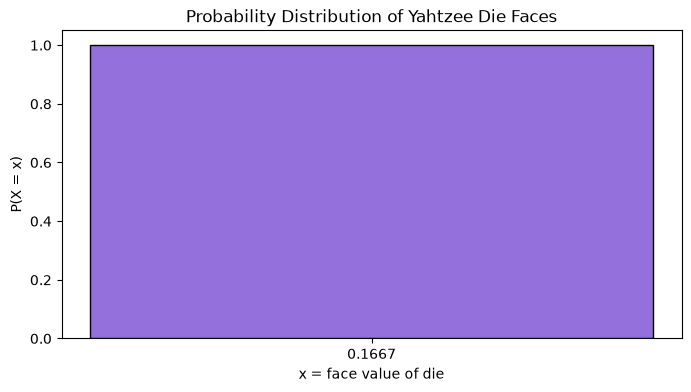

In [51]:
plt.figure(figsize=(8, 4))
plt.bar(
    dist['x (face value)'],
    dist['P(X = x)'],
    color='mediumpurple',
    edgecolor='black',
)
plt.xlabel('x = face value of die')
plt.ylabel('P(X = x)')
plt.title('Probability Distribution of Yahtzee Die Faces')
plt.xticks(dist['x (face value)'])
plt.show()

In [52]:
def p(x):
    point_counts.get(x, 0) / total_outcomes

In [53]:
print("P(X = 5) =", p(5))
print("P(X = 1) =", p(1))
print("P(X = 7) =", p(7), " ← no die face is worth 7")

P(X = 5) = None
P(X = 1) = None
P(X = 7) = None  ← no die face is worth 7


In [54]:
dist['P(X ≤ x)'] = dist['P(X = x)'].cumsum().round(2)
dist

,x (face value),sides,P(X = x),P(X ≤ x)
0,0.166667,30,1.0,1.0


In [71]:
point_counts = {1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1}
total_outcomes = sum(point_counts.values())
def p(x):
    point_counts.get(x, 0) / total_outcomes

In [87]:
def F(x):
    round(sum(p+x) for x in point_counts if p < x), 2

In [89]:
for trial in range(1, 6):
    sample = [dice_faces[face][1] for face in rng.choice(bag, size=200)]
    print(f"Simulation {trial}: average face value = {np.mean(sample):.3f}")

Simulation 1: average face value = 0.167
Simulation 2: average face value = 0.167
Simulation 3: average face value = 0.167
Simulation 4: average face value = 0.167
Simulation 5: average face value = 0.167


In [91]:
dist['x · P(x)'] = dist['x (face value)'] * dist['P(X = x)']
display(dist[['x (face value)', 'P(X = x)', 'x · P(x)']])

,x (face value),P(X = x),x · P(x)
0,0.166667,1.0,0.166667


In [92]:
mu = dist['x · P(x)'].sum()
print(f"Expected value: μ_X = {mu:.2f} face value")

Expected value: μ_X = 0.17 face value


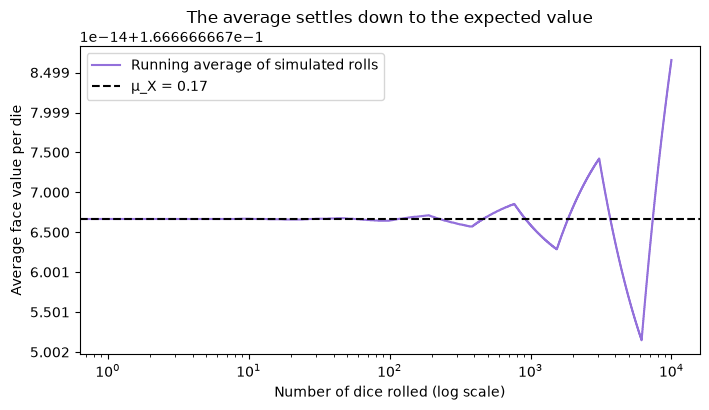

In [94]:
running_avg = np.cumsum(sim_X) / np.arange(1, n_draws + 1)

plt.figure(figsize=(8, 4))
plt.plot(
    running_avg, color='mediumpurple', label='Running average of simulated rolls'
)
plt.axhline(mu, color='black', linestyle='--', label=f'μ_X = {mu:.2f}')
plt.xscale('log')
plt.xlabel('Number of dice rolled (log scale)')
plt.ylabel('Average face value per die')
plt.title('The average settles down to the expected value')
plt.legend()
plt.show()

In [95]:
dist['(x − μ)² · P(x)'] = (dist['x (face value)'] - mu) ** 2 * dist['P(X = x)']
display(dist[['x (face value)', 'P(X = x)', '(x − μ)² · P(x)']].round(4))

,x (face value),P(X = x),(x − μ)² · P(x)
0,0.1667,1.0,0.0


In [96]:
variance = dist['(x − μ)² · P(x)'].sum()
sigma = np.sqrt(variance)
print(f"Variance:           σ²_X = {variance:.4f}")
print(f"Standard deviation: σ_X  = {sigma:.2f} face value")

Variance:           σ²_X = 0.0000
Standard deviation: σ_X  = 0.00 face value


In [97]:
print(f"Simulated mean: {sim_X.mean():.2f}   (parameter μ_X = {mu:.2f})")
print(f"Simulated SD:   {sim_X.std():.2f}   (parameter σ_X = {sigma:.2f})")

Simulated mean: 0.17   (parameter μ_X = 0.17)
Simulated SD:   0.00   (parameter σ_X = 0.00)


## Conculsion

The theoretical probability distrabution for a single 6-sided dice roll is 0.167 Across a larger scale the empirical running average the expected value is about 8.5 for the average face value per die. It's because having rolled three 5s in your first three rolls does not affect the outcome of the remaining two dice it's also because each dice roll is an independent event, the probability of rolling a 5 on a single standard 6-sided die remains 1 in 6, or approximately 16.67%. To calculate the probability of rolling a 5 on both of the remaining two dice, you multiply their individual probabilities together which equals 1 in 36, or approximately 2.78%.